In [53]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [54]:
df = pd.read_csv("spam.csv",encoding="latin-1")
print(df.shape)

(5572, 5)


In [55]:
df = df[["v1", "v2"]]
df.columns = ["label", "text"]
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)

Duplicates: 404
(5168, 2)


In [56]:
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [57]:
df["label"].value_counts()

label
ham     4516
spam     652
Name: count, dtype: int64

In [58]:
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
df["label_num"].isnull().sum()

np.int64(0)

In [59]:
X = df["text"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(4134,) (1034,)


In [60]:
tfidf = TfidfVectorizer()
X_train_t = tfidf.fit_transform(X_train)
X_test_t = tfidf.transform(X_test)
print(X_train_t.shape, X_test_t.shape)

(4134, 7570) (1034, 7570)


In [61]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_t, y_train)
y_pred = model.predict(X_test_t)

In [62]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

Accuracy: 0.9700193423597679
[[903   1]
 [ 30 100]]
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       904
        spam       0.99      0.77      0.87       130

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034



In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import os
os.makedirs("images", exist_ok=True)

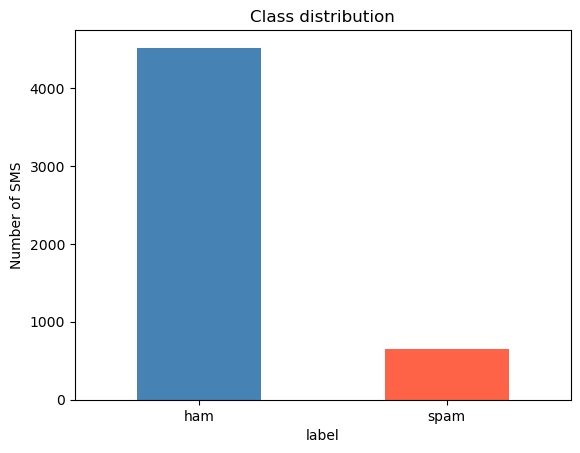

In [64]:
df["label"].value_counts().plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Class distribution")
plt.ylabel("Number of SMS")
plt.xticks(rotation=0)
plt.savefig("images/class_distribution.png", bbox_inches="tight")
plt.show()

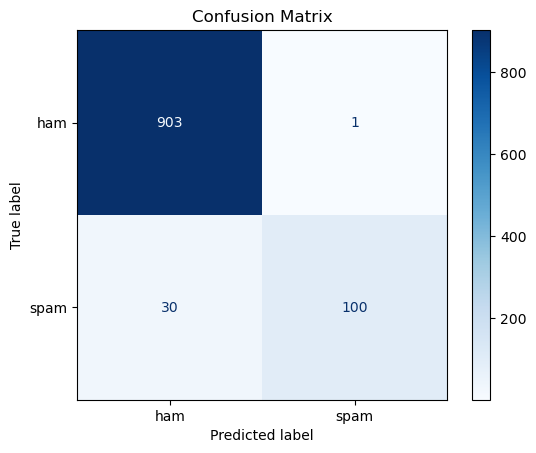

In [65]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["ham", "spam"], cmap="Blues"
)
plt.title("Confusion Matrix")
plt.savefig("images/confusion_matrix.png", bbox_inches="tight")
plt.show()

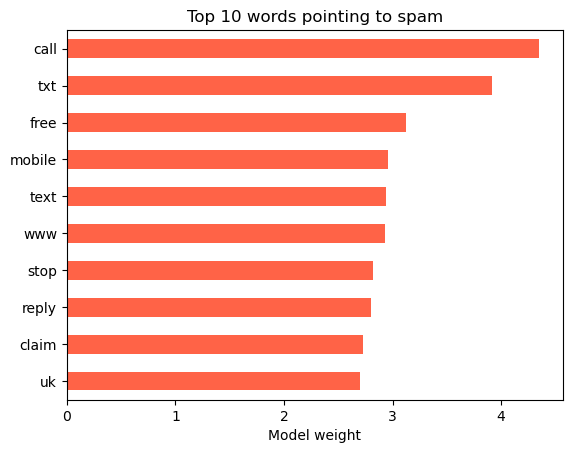

In [66]:
import pandas as pd
words = tfidf.get_feature_names_out()
coefs = model.coef_[0]
top = pd.Series(coefs, index=words).sort_values(ascending=False).head(10)

top.sort_values().plot(kind="barh", color="tomato")
plt.title("Top 10 words pointing to spam")
plt.xlabel("Model weight")
plt.savefig("images/top_spam_words.png", bbox_inches="tight")
plt.show()